In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [3]:
df = pd.read_csv("datasets/creditcard/creditcard.csv")

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,0.091,-0.552,-0.618,-0.991,-0.311,1.468,-0.470,0.208,0.026,0.404,0.251,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,-0.167,1.613,1.065,0.489,-0.144,0.636,0.464,-0.115,-0.183,-0.146,-0.069,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0
2,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,0.208,0.625,0.066,0.717,-0.166,2.346,-2.890,1.110,-0.121,-2.262,0.525,0.248,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0
3,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,-0.055,-0.226,0.178,0.508,-0.288,-0.631,-1.060,-0.684,1.966,-1.233,-0.208,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0
4,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,0.753,-0.823,0.538,1.346,-1.120,0.175,-0.451,-0.237,-0.038,0.803,0.409,-0.009,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0


In [5]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'], dtype='object')

In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000
mean,94813.860,0.000,0.000,-0.000,0.000,0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000,0.000,-0.000,-0.000,88.350,0.002
std,47488.146,1.959,1.651,1.516,1.416,1.380,1.332,1.237,1.194,1.099,1.089,1.021,0.999,0.995,0.959,0.915,0.876,0.849,0.838,0.814,0.771,0.735,0.726,0.624,0.606,0.521,0.482,0.404,0.330,250.120,0.042
min,0.000,-56.408,-72.716,-48.326,-5.683,-113.743,-26.161,-43.557,-73.217,-13.434,-24.588,-4.797,-18.684,-5.792,-19.214,-4.499,-14.130,-25.163,-9.499,-7.214,-54.498,-34.830,-10.933,-44.808,-2.837,-10.295,-2.605,-22.566,-15.430,0.000,0.000
25%,54201.500,-0.920,-0.599,-0.890,-0.849,-0.692,-0.768,-0.554,-0.209,-0.643,-0.535,-0.762,-0.406,-0.649,-0.426,-0.583,-0.468,-0.484,-0.499,-0.456,-0.212,-0.228,-0.542,-0.162,-0.355,-0.317,-0.327,-0.071,-0.053,5.600,0.000
50%,84692.000,0.018,0.065,0.180,-0.020,-0.054,-0.274,0.040,0.022,-0.051,-0.093,-0.033,0.140,-0.014,0.051,0.048,0.066,-0.066,-0.004,0.004,-0.062,-0.029,0.007,-0.011,0.041,0.017,-0.052,0.001,0.011,22.000,0.000
75%,139320.500,1.316,0.804,1.027,0.743,0.612,0.399,0.570,0.327,0.597,0.454,0.740,0.618,0.663,0.493,0.649,0.523,0.400,0.501,0.459,0.133,0.186,0.529,0.148,0.440,0.351,0.241,0.091,0.078,77.165,0.000
max,172792.000,2.455,22.058,9.383,16.875,34.802,73.302,120.589,20.007,15.595,23.745,12.019,7.848,7.127,10.527,8.878,17.315,9.254,5.041,5.592,39.421,27.203,10.503,22.528,4.585,7.520,3.517,31.612,33.848,25691.160,1.000


In [7]:
df['Class'].value_counts(normalize=True)

Class
0   0.998
1   0.002
Name: proportion, dtype: float64

Missing values

In [8]:
missing = df.isnull().sum()
if missing.any():
    print("\nEksik değerler:")
    print(missing[missing > 0])
else:
    print("\nEksik değer yok")



Eksik değer yok


In [9]:
# 2. Özellik dağılımları ve korelasyonlar
def feature_analysis(df):
    # Sayısal değişkenlerin dağılımı
    plt.figure(figsize=(15, 6))
    
    # Amount için histogram
    plt.subplot(1, 2, 1)
    sns.histplot(data=df, x='Amount', hue='Class', bins=50)
    plt.title('Amount Distribution by Class')
    plt.yscale('log')  # Log scale for better visualization
    
    # Korelasyon matrisi
    plt.subplot(1, 2, 2)
    corr_with_class = df.corr()['Class'].sort_values(ascending=False)
    sns.barplot(x=corr_with_class.index[:10], y=corr_with_class.values[:10])
    plt.xticks(rotation=45)
    plt.title('Top 10 Correlations with Class')
    
    plt.tight_layout()
    plt.show()

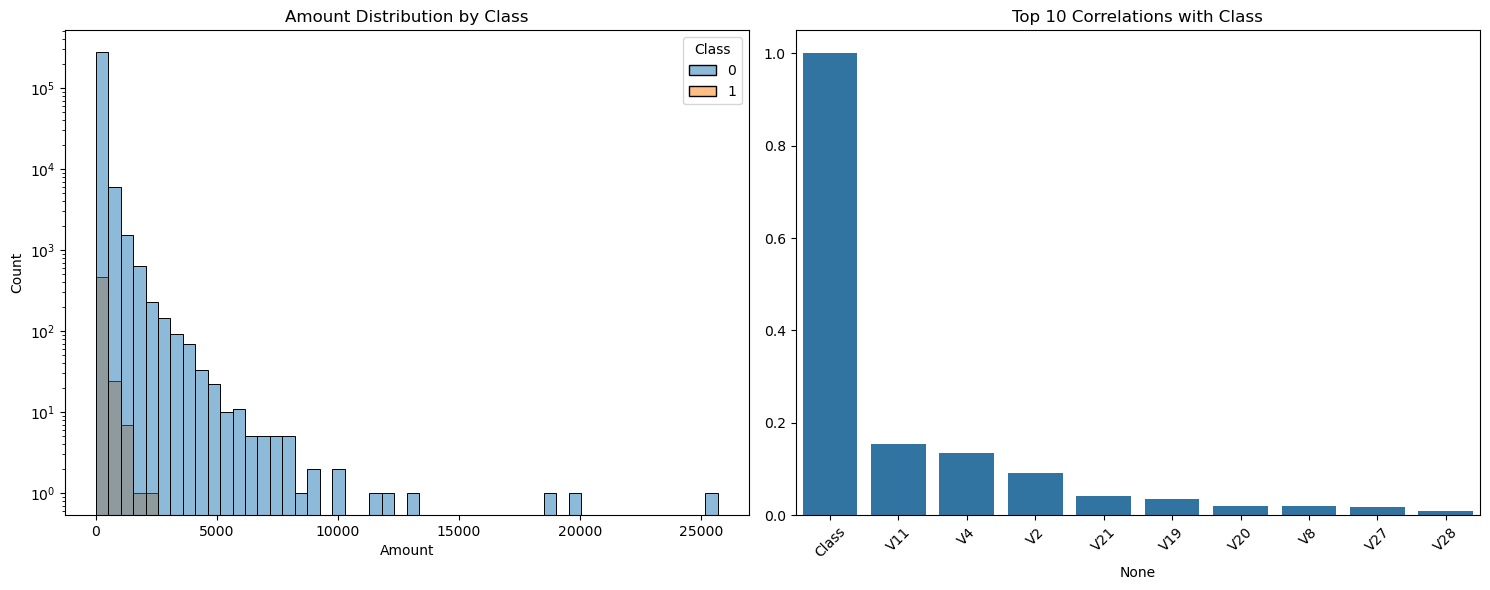

In [10]:
feature_analysis(df)

Feature Engineering

In [11]:
df['LogAmount'] = np.log1p(df['Amount'])

In [12]:
df['AmountZScore'] = stats.zscore(df['Amount'])

In [13]:
# V1-V28 aggregated features
v_cols = [col for col in df.columns if col.startswith('V')]
df['V_mean'] = df[v_cols].mean(axis=1)
df['V_std'] = df[v_cols].std(axis=1)

In [14]:
X = df.drop(columns=['Class'])
y = df['Class']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [16]:
# Scaling
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

In [17]:
# SMOTE ve Auto-sklearn için gerekli kütüphaneleri içe aktaralım
from imblearn.over_sampling import SMOTE
from autosklearn.classification import AutoSklearnClassifier
import time
from sklearn.metrics import accuracy_score, classification_report

In [18]:
# SMOTE uygulama
print("SMOTE uygulanıyor...")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

SMOTE uygulanıyor...


In [19]:
print("SMOTE sonrası sınıf dağılımı:")
print(pd.Series(y_train_smote).value_counts(normalize=True))

SMOTE sonrası sınıf dağılımı:
Class
0   0.500
1   0.500
Name: proportion, dtype: float64


In [31]:
import autosklearn
import autosklearn.metrics

In [38]:
# Auto-sklearn modelini oluşturma
automl = autosklearn.classification.AutoSklearnClassifier(
    time_left_for_this_task=3600,
    per_run_time_limit=300,
    ensemble_size=50,  # Ensemble boyutunu direkt burada belirtiyoruz
    metric=autosklearn.metrics.f1,
    memory_limit=6144,  # 6GB RAM limiti
    n_jobs=1,  # Tek iş parçacığı kullan
    resampling_strategy='cv',
    resampling_strategy_arguments={'folds': 5},
    initial_configurations_via_metalearning=0,
    include={
        'classifier': [
            'random_forest',
            'gradient_boosting',
            'libsvm_svc',
            'sgd',
            'extra_trees'
        ]
    }
)

/tmp/ipykernel_20474/2716811483.py:2: DeprecationWarning: `ensemble_size` has been deprecated, please use `ensemble_kwargs = {'ensemble_size': 50}`. Inserting `ensemble_size` into `ensemble_kwargs` for now. `ensemble_size` will be removed in auto-sklearn 0.16.
  automl = autosklearn.classification.AutoSklearnClassifier(


In [39]:
# Modeli eğitme ve süreyi ölçme
print("\nModel eğitimi başlıyor...")
baslangic_zamani = time.time()

# Veriyi float32'ye dönüştür (bellek kullanımını azaltmak için)
X_train_smote = X_train_smote.astype('float32')
y_train_smote = y_train_smote.astype('int32')

try:
    # Modeli eğit ve tahminleri yap
    automl.fit(X_train_smote, y_train_smote, dataset_name='credit_card_fraud')
    
    bitis_zamani = time.time()
    egitim_suresi = bitis_zamani - baslangic_zamani
    print(f"\nEğitim süresi: {egitim_suresi:.2f} saniye ({egitim_suresi/60:.2f} dakika)")
    
    # Model performansını değerlendir
    y_pred = automl.predict(X_test)
    print("\nSınıflandırma Raporu:")
    print(classification_report(y_test, y_pred))
    
    # Show the models found
    print("\nEn iyi modeller ve performansları:")
    print(automl.leaderboard())
    
    # Show statistics about the search
    print("\nModel istatistikleri:")
    print(automl.sprint_statistics())
    
    # Show the final ensemble composition
    print("\nEnsemble yapısı:")
    print(automl.show_models())
    
except Exception as e:
    print(f"Bir hata oluştu: {str(e)}")
    print("\nStack trace:")
    import traceback
    traceback.print_exc()


Model eğitimi başlıyor...

Eğitim süresi: 3591.76 saniye (59.86 dakika)

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962


En iyi modeller ve performansları:
          rank  ensemble_weight  type  cost duration
model_id                                            
1            1            1.000  <NA>  <NA>     <NA>

Model istatistikleri:
auto-sklearn results:
  Dataset name: credit_card_fraud
  Metric: f1
  Number of target algorithm runs: 1236
  Number of successful target algorithm runs: 0
  Number of crashed target algorithm runs: 1236
  Number of target algorithms that exceeded the time limit: 0
  Number of target algorithms that exceeded the memory limit: 0


Ensemble yapısı:
Bir hata 

/root/miniconda3/envs/autosklearn/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  labels=labels, samplewise=samplewise)
/root/miniconda3/envs/autosklearn/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  labels=labels, samplewise=samplewise)
/root/miniconda3/envs/autosklearn/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  labels=labels, samplewise=samplewise)
Traceback (most recent call last):
  File "

In [39]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import tensorflow as tf

In [40]:
models = {
    'XGBoost': XGBClassifier(
        scale_pos_weight=len(y_train[y_train==0])/len(y_train[y_train==1]),
        random_state=42,
        tree_method='gpu_hist',
        predictor='gpu_predictor',
        gpu_id=0
    ),
    
    'LightGBM': LGBMClassifier(
        class_weight='balanced',
        random_state=42,
        device='gpu',
        gpu_platform_id=0,
        gpu_device_id=0
    ),
}

In [41]:
results = {}

In [42]:
from sklearn.metrics import average_precision_score, classification_report, precision_recall_curve

Training XGBoost model...


/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [01:36:07] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)
/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [01:36:07] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "predictor" } are not used.

  warnings.warn(smsg, UserWarning)
/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [01:36:08] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)


XGBoost AUPRC: 0.876

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.89      0.84      0.86        98

    accuracy                           1.00     56962
   macro avg       0.95      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962

Train-Test Split Oranları:
Train set class distribution:
Class
0   0.998
1   0.002
Name: proportion, dtype: float64
Test set class distribution:
Class
0   0.998
1   0.002
Name: proportion, dtype: float64

Top 10 Important Features:
   feature  importance
14     V14       0.604
4       V4       0.056
12     V12       0.034
33   V_std       0.029
10     V10       0.027
8       V8       0.019
7       V7       0.017
29  Amount       0.016
13     V13       0.015
20     V20       0.014


/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [01:36:09] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)
/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [01:36:09] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "predictor" } are not used.

  warnings.warn(smsg, UserWarning)
/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning: [01:36:09] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)
/home/gurkantngl/.local/lib/python3.11/site-packages/xgboost/core.py:158: UserWarning


Cross-validation F1 scores: [0.9092476  0.93780408 0.90893704 0.9412859  0.93034818]
Mean CV F1: 0.9255245589987633


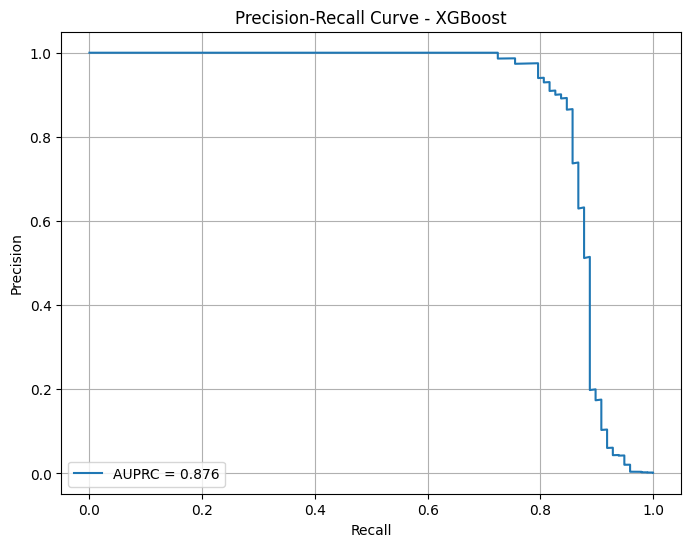

Training LightGBM model...
[LightGBM] [Info] Number of positive: 394, number of negative: 227451
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 8670
[LightGBM] [Info] Number of data points in the train set: 227845, number of used features: 34
[LightGBM] [Info] Using requested OpenCL platform 0 device 0
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce GTX 1650 Ti, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 34 dense feature groups (7.82 MB) transferred to GPU in 0.012713 secs. 0 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
LightGBM AUPRC: 0.855

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82 

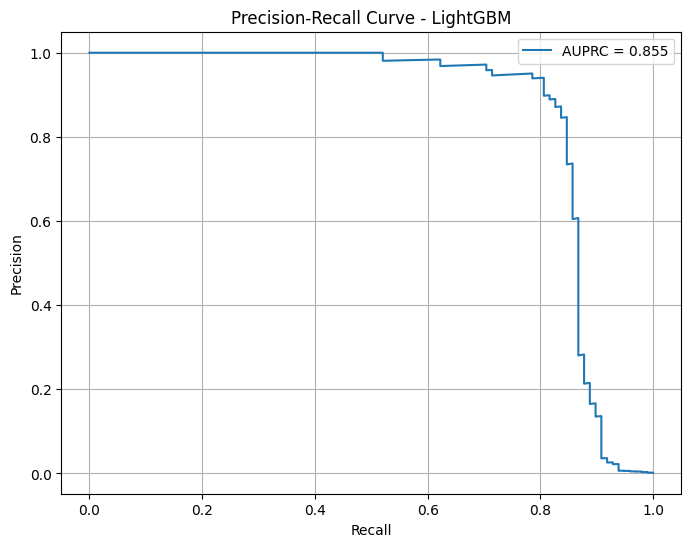

In [43]:
for name, model in models.items():
    print(f"Training {name} model...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        'auprc': average_precision_score(y_test, y_pred_proba),
        'classification_report': classification_report(y_test, y_pred)
    }

    print(f"{name} AUPRC: {results[name]['auprc']:.3f}")
    print("\nClassification Report:")
    print(results[name]['classification_report'])


        # 1. Train-Test Split kontrolü
    print("Train-Test Split Oranları:")
    print(f"Train set class distribution:\n{y_train.value_counts(normalize=True)}")
    print(f"Test set class distribution:\n{y_test.value_counts(normalize=True)}")

    # 2. Feature importance kontrolü
    if hasattr(model, 'feature_importances_'):
        importances = pd.DataFrame({
            'feature': X_train.columns,
            'importance': model.feature_importances_
        }).sort_values('importance', ascending=False)
        print("\nTop 10 Important Features:")
        print(importances.head(10))

    # 3. Cross-validation sonuçları
    from sklearn.model_selection import cross_val_score
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1_macro')
    print("\nCross-validation F1 scores:", cv_scores)
    print("Mean CV F1:", cv_scores.mean())


    precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
    
    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, label=f'AUPRC = {average_precision_score(y_test, y_pred_proba):.3f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve - {name}')
    plt.legend()
    plt.grid(True)
    plt.show()
